In [2]:
#pip install numpy pandas matplotlib seaborn scikit-learn

In [4]:
#Libraries Importing:

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error, r2_score


In [80]:
#DataSets Importing:

In [82]:
file_path = "/Users/adityavardhan/Library/Mobile Documents/com~apple~CloudDocs/ML Assignment/cw1data.csv"

df = pd.read_csv(file_path)

df.head()


,y,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13
0,49.83,1.68,82.8,24,6.554,6.538,6.438,6.390,6.318,29.44,39.83,59.10,54.11,40.72
1,50.12,1.71,86.5,53,6.593,6.578,6.465,6.420,6.356,19.11,40.19,57.34,53.60,39.24
2,49.02,1.65,91.0,45,6.488,6.466,6.360,6.313,6.251,31.00,41.56,56.69,50.99,38.08
3,61.70,1.69,100.7,42,6.361,6.334,6.209,6.160,6.087,33.39,44.33,52.26,45.33,29.23
4,40.83,1.72,62.3,37,6.667,6.644,6.539,6.491,6.417,34.33,48.35,69.03,62.02,44.97


In [84]:
#Basic Data Check

In [10]:
print(df.shape)
print(df.info())
print(df.describe())


(135, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   y       135 non-null    float64
 1   x1      135 non-null    float64
 2   x2      135 non-null    float64
 3   x3      135 non-null    int64  
 4   x4      135 non-null    float64
 5   x5      135 non-null    float64
 6   x6      135 non-null    float64
 7   x7      135 non-null    float64
 8   x8      135 non-null    float64
 9   x9      135 non-null    float64
 10  x10     135 non-null    float64
 11  x11     135 non-null    float64
 12  x12     135 non-null    float64
 13  x13     135 non-null    float64
dtypes: float64(13), int64(1)
memory usage: 14.9 KB
None
                y          x1          x2          x3          x4          x5  \
count  135.000000  135.000000  135.000000  135.000000  135.000000  135.000000   
mean    55.147333    1.621556   97.740000   44.859259    6.308985    6.284

In [86]:
#Checking the missing values:

print(df.isnull().sum())


y      0
x1     0
x2     0
x3     0
x4     0
x5     0
x6     0
x7     0
x8     0
x9     0
x10    0
x11    0
x12    0
x13    0
dtype: int64


In [54]:
#Data Visualization :

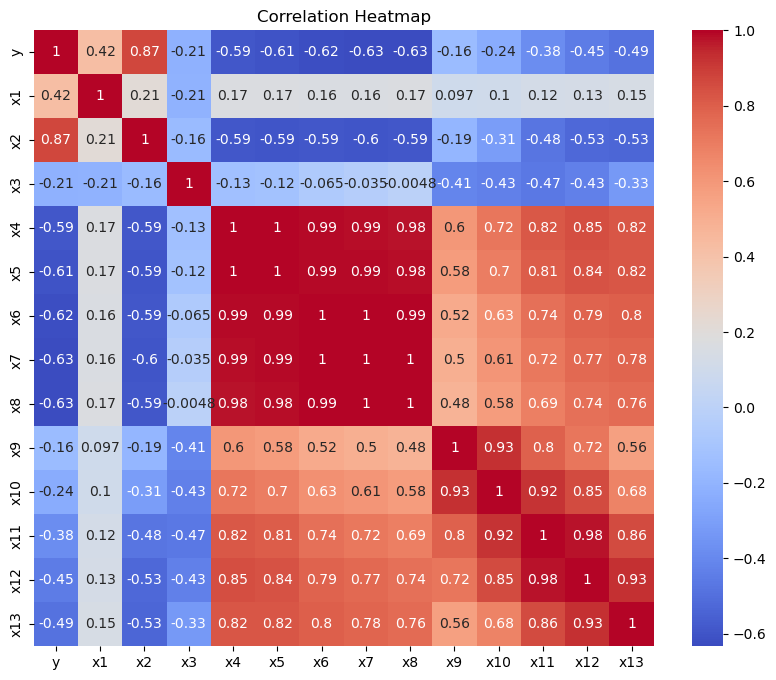

In [88]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


In [90]:
#Define Input and Output
X = df.drop("y", axis=1)
y = df["y"]



In [92]:
#Train/Test Split:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [94]:
#Data Scaling :
scaler = StandardScaler()
 

In [96]:
#Training Multiple Linear Models(Linear Regression, Ridge Regression, Lasso Regression, ElasticNet, Polynomial Regression) and Random forest

In [98]:
models = {
    "Linear Regression":
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LinearRegression())
        ]),

    "Ridge Regression":
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=1.0))
        ]),

    "Lasso Regression":
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", Lasso(alpha=0.1))
        ]),

    "ElasticNet":
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", ElasticNet(alpha=0.1, l1_ratio=0.5))
        ]),

    "Polynomial Regression":
        Pipeline([
            ("scaler", StandardScaler()),
            ("poly", PolynomialFeatures(degree=2)),
            ("model", LinearRegression())
        ]),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=200,
            random_state=42
        )
}


In [100]:
results = []

for name, model in models.items():
    
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)

    results.append([name, mse, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=["Model", "MSE", "RMSE", "R2"]
)

results_df.sort_values("R2", ascending=False)



,Model,MSE,RMSE,R2
0,Linear Regression,7.462779,2.731809,0.882120
2,Lasso Regression,7.573210,2.751947,0.880376
1,Ridge Regression,7.587227,2.754492,0.880154
3,ElasticNet,7.699329,2.774766,0.878384
5,Random Forest,11.194739,3.345854,0.823171
4,Polynomial Regression,6831.799454,82.654700,-106.913149


In [102]:
#Cross Validation:

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring="r2")
    print(name, "CV R2:", scores.mean())



Linear Regression CV R2: 0.8190711938920743
Ridge Regression CV R2: 0.8573331611470596
Lasso Regression CV R2: 0.8631948941660218
ElasticNet CV R2: 0.8625098550868531
Polynomial Regression CV R2: -403.8105666486563
Random Forest CV R2: 0.7361594839409373


In [104]:
#Selecting the Best Model:

best_model_name = results_df.sort_values(
    "R2", ascending=False
).iloc[0]["Model"]

print("Best Model:", best_model_name)



Best Model: Linear Regression


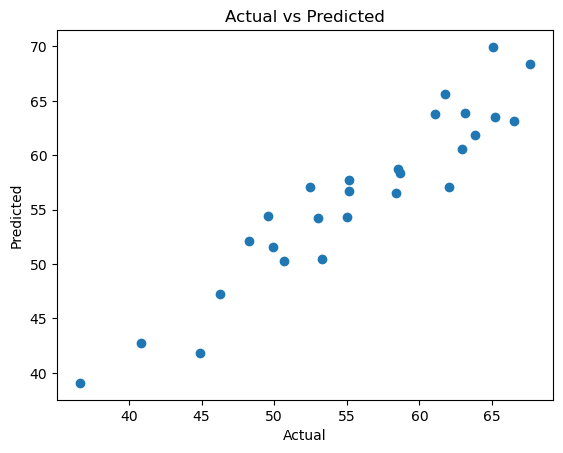

In [76]:
#Prediction Visualization:

best_model = models[best_model_name]
best_model.fit(X_train, y_train)

preds = best_model.predict(X_test)

plt.scatter(y_test, preds)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()
